In [ ]:
!pip install opendatasets

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import opendatasets as od
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor,AdaBoostRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score,accuracy_score

In [ ]:
od.download('https://www.kaggle.com/datasets/harishkumardatalab/housing-price-prediction/croissant/download')

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: qwerty
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/harishkumardatalab/housing-price-prediction


100%|██████████| 4.63k/4.63k [00:00<00:00, 8.06MB/s]

In [ ]:
df = pd.read_csv('/content/housing-price-prediction/Housing.csv')

In [ ]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [ ]:
bedrooms_count = df['bedrooms'].value_counts()
bedrooms_count

,count
bedrooms,
3,300
2,136
4,95
5,10
6,2
1,2


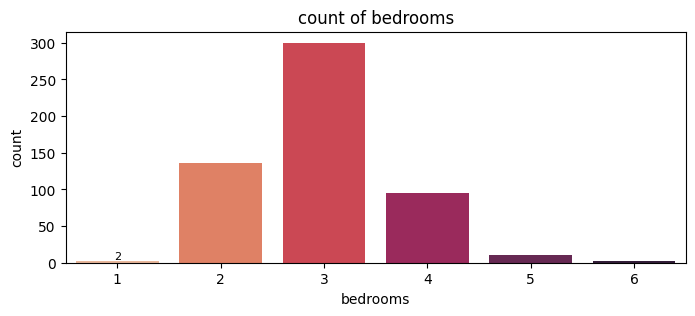

In [ ]:
plt.figure(figsize=(8,3))
ax=sns.barplot(x=bedrooms_count.index, y=bedrooms_count.values,palette="rocket_r")
ax.bar_label(ax.containers[0], fontsize=8);
plt.title('count of bedrooms')
plt.xlabel('bedrooms')
plt.ylabel('count')
plt.show()

In [ ]:
count_bathrooms = df['bathrooms'].value_counts()
count_bathrooms

,count
bathrooms,
1,401
2,133
3,10
4,1


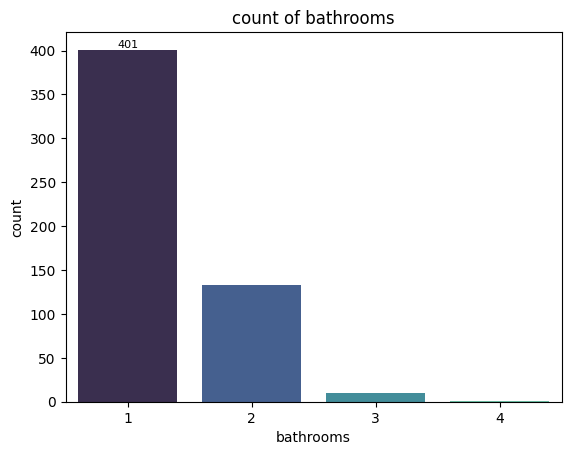

In [ ]:
ax = sns.barplot(x=count_bathrooms.index,y=count_bathrooms.values,palette="mako")
ax.bar_label(ax.containers[0], fontsize=8);
plt.title('count of bathrooms')
plt.xlabel('bathrooms')
plt.ylabel('count')
plt.show()

In [ ]:
stories_count = df['stories'].value_counts()
stories_count

,count
stories,
2,238
1,227
4,41
3,39


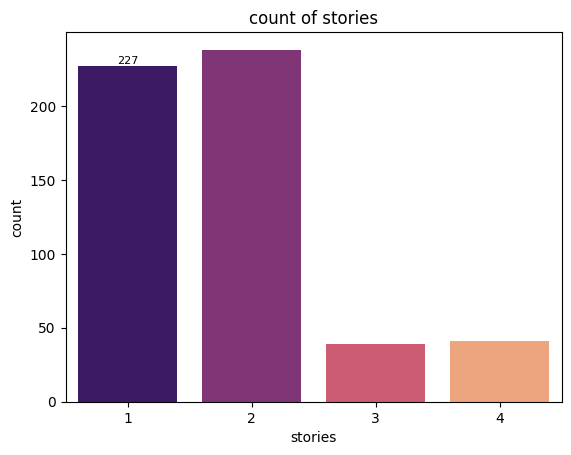

In [ ]:
ax = sns.barplot(x=stories_count.index,y=stories_count.values,palette="magma")
ax.bar_label(ax.containers[0], fontsize=8)
plt.title('count of stories')
plt.xlabel('stories')
plt.ylabel('count')
plt.show()

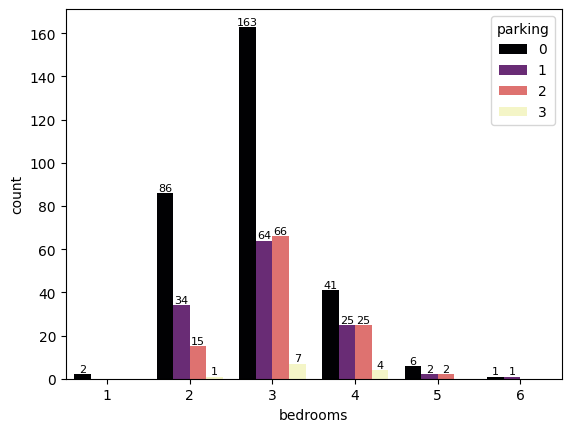

In [ ]:
ax = sns.countplot(df, x="bedrooms", hue="parking",palette="magma")
for i in range(len(df['parking'].unique())):
    ax.bar_label(ax.containers[i], fontsize=8)


plt.show()

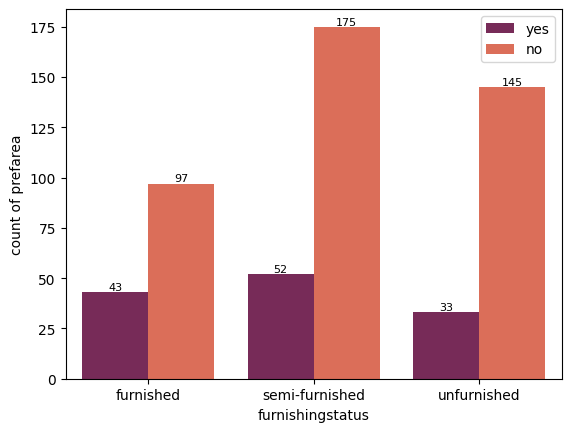

In [ ]:
ax = sns.countplot(df, x="furnishingstatus", hue="prefarea",palette="rocket")
for i in range(len(df['prefarea'].unique())):
    ax.bar_label(ax.containers[i], fontsize=8)
plt.ylabel('count of prefarea')
plt.legend(loc = 'best')
plt.show()

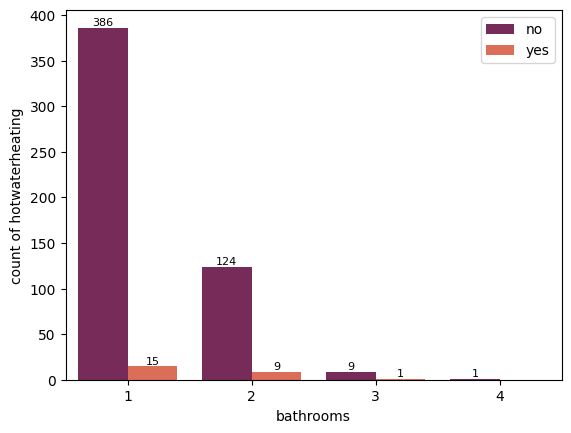

In [ ]:
ax = sns.countplot(df, x="bathrooms", hue="hotwaterheating",palette="rocket")
for i in range(len(df['hotwaterheating'].unique())):
    ax.bar_label(ax.containers[i], fontsize=8)
plt.ylabel('count of hotwaterheating')
plt.legend(loc = 'best')
plt.show()

In [ ]:
encoder = LabelEncoder()

encoding_col = ['furnishingstatus','prefarea','airconditioning','hotwaterheating','basement','guestroom','mainroad']
for col in encoding_col:
    df[col]=encoder.fit_transform(df[col])

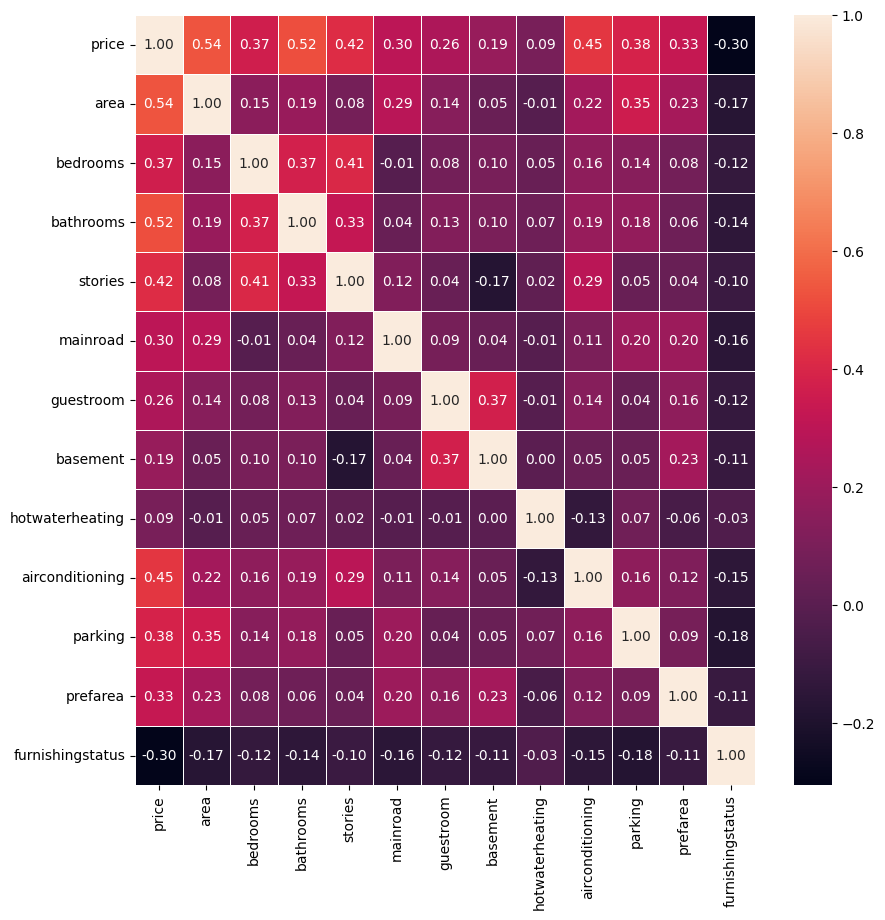

In [ ]:
plt.figure(figsize=(10, 10))
sns.heatmap(df.corr(), annot=True, fmt=".2f", linewidths=0.5, cbar=True)
plt.show()

In [ ]:
x=df.drop(columns=['price'],axis = 1)
y=df['price']

In [ ]:
scaler = MinMaxScaler()
x = scaler.fit_transform(x)
y = scaler.fit_transform(y.values.reshape(-1, 1))

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=50)

In [ ]:
ln_model = LinearRegression()
ln_model.fit(x_train, y_train)

y_pred = ln_model.predict(x_test)

print(f'r2 score : {r2_score(y_test, y_pred)}')
print(f'mae : {mean_absolute_error(y_test, y_pred)}')
print(f'mse : {mean_squared_error(y_test, y_pred)}')


r2 score : 0.7624579467323475
mae : 0.06332171625253742
mse : 0.006055724882518719


In [ ]:
dt_model = DecisionTreeRegressor()
dt_model.fit(x_train, y_train)

y_pred = dt_model.predict(x_test)

print(f'r2 score : {r2_score(y_test, y_pred)}')
print(f'mae : {mean_absolute_error(y_test, y_pred)}')
print(f'mse : {mean_squared_error(y_test, y_pred)}')


r2 score : 0.23028061242519693
mae : 0.09655223797609118
mse : 0.019622668002459962


In [ ]:
rf_model = RandomForestRegressor(n_estimators=100)
rf_model.fit(x_train,y_train)

y_pred = rf_model.predict(x_test)

print(f'r2 score : {r2_score(y_test, y_pred)}')
print(f'mae : {mean_absolute_error(y_test, y_pred)}')
print(f'mse : {mean_squared_error(y_test, y_pred)}')


r2 score : 0.7334493248801697
mae : 0.06195639765942519
mse : 0.006795249656095858


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators = 50,
)

gb_model.fit(x_train,y_train)

y_pred=gb_model.predict(x_test)

print(f'r2 score : {r2_score(y_test, y_pred)}')
print(f'mae : {mean_absolute_error(y_test, y_pred)}')
print(f'mse : {mean_squared_error(y_test, y_pred)}')

r2 score : 0.7100186027886299
mae : 0.06658074187519351
mse : 0.007392575497281721


In [ ]:
import pandas as pd

# Get the first 5 actual values from y_test (inverse transformed)
actual_prices_scaled = y_test[:5]
actual_prices = scaler.inverse_transform(actual_prices_scaled).flatten()

# Get the first 5 feature sets from x_test
x_test_first_5 = x_test[:5]

# Predict prices for these 5 feature sets using the linear regression model
predicted_prices_scaled = ln_model.predict(x_test_first_5)

# Inverse transform the predicted prices to their original scale
predicted_prices = scaler.inverse_transform(predicted_prices_scaled.reshape(-1, 1)).flatten()

# Create a DataFrame to display the results
results_df = pd.DataFrame({
    'Actual Price': actual_prices,
    'Predicted Price': predicted_prices
})

print("Actual vs. Predicted Prices (First 5 Test Samples):")
print(results_df.round(2))

Actual vs. Predicted Prices (First 5 Test Samples):
   Actual Price  Predicted Price
0     3920000.0       3358069.37
1     7980000.0       8464192.60
2     3500000.0       3205430.85
3     2730000.0       3436227.32
4     1960000.0       2972460.47


In [ ]:
import pickle
from google.colab import files

with open('linear_regression_model.pkl', 'wb') as f:
    pickle.dump(ln_model, f)

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print("Model and Scaler have been saved as .pkl files.")

files.download('linear_regression_model.pkl')
files.download('scaler.pkl')

Model and Scaler have been saved as .pkl files.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>